# FedAvg with IID MNIST

This notebook runs all 25 clients in every round. It supports `cnn` and `resnet_linear` modes, uses GPU tensors instead of PIL/DataLoader preprocessing, saves metrics after every round, and keeps a single `checkpoint_last.pt` updated after every round.

Results, checkpoint, and metrics for each run are stored in `PROJECT_ROOT/baseline/run{run_id}`.

- Bắt đầu thí nghiệm mới: Đặt `RUN_ID` thành một số mới (ví dụ `1`, `2`, `3`...).
- Tiếp tục huấn luyện (resume hoặc tăng `ROUNDS`): Giữ nguyên `RUN_ID`. Notebook sẽ tự động phát hiện `checkpoint_last.pt`, kiểm tra cấu hình có bị thay đổi không, và chạy tiếp liền mạch.


In [1]:
import csv
import hashlib
import json
import os
import random
import tarfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, models

assert torch.cuda.is_available(), 'Enable the T4 GPU in Colab before running this notebook.'
DEVICE = torch.device('cuda')
torch.backends.cudnn.benchmark = True
print(torch.cuda.get_device_name(0))


Tesla T4


In [ ]:
# Main configuration
MODEL_NAME = 'cnn'  # 'cnn', 'logreg_raw', or 'resnet_linear'
DATASET_NAME = 'mnist'  # 'mnist' or 'cifar10'
IMBALANCE_MODE = 'Global'  # 'None' or 'Global'
#DATASET_NAME = 'cifar10'  # 'mnist' or 'cifar10'
#MODEL_NAME = 'logreg_raw'  # 'cnn', 'logreg_raw', or 'resnet_linear'
#MODEL_NAME = 'resnet_linear'  # 'cnn', 'logreg_raw', or 'resnet_linear'

NUM_CLIENTS = 25
CLIENTS_PER_ROUND = 25
ROUNDS = 50
LOCAL_EPOCHS = 3
BATCH_SIZE = 64
LEARNING_RATE = 0.01
RESNET_SIZE = 112  # use 224 for the standard ImageNet input size
EMBED_BATCH_SIZE = 256
EVAL_BATCH_SIZE = 4096

# Số mẫu mỗi class khi IMBALANCE_MODE = 'Global'
SAMPLES_PER_CLASS = {
    0: 5900, 1: 5900, 2: 5300, 3: 4100, 4: 2900,
    5: 2100, 6: 1400, 7: 900, 8: 600, 9: 300,
}

PARTITION_SEED = 42
MODEL_SEED = 42
BATCH_SEED = 42
SELECTION_SEED = 43

# Run configuration
RUN_ID = '14'      # dedicated Global-imbalance baseline run
# Tự động tiếp tục: Nếu run{RUN_ID} đã có checkpoint_last.pt, code sẽ tự động kiểm tra cấu hình và chạy tiếp.

# Drive / local path setup with fallback
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/FLasIRL(new)')
except ImportError:
    print('Not running in Colab; using local directory fallback.')
    PROJECT_ROOT = Path.cwd() / 'FLasIRL(new)' if not Path('/content').exists() else Path('/content/FLasIRL(new)')

if not PROJECT_ROOT.parent.exists():
    PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / 'data' / DATASET_NAME
PARTITION_DIR = DATA_DIR / 'partitions' / 'IID'
BASELINE_DIR = PROJECT_ROOT / 'baseline'

for folder in [DATA_DIR, PARTITION_DIR, BASELINE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Determine run directory: PROJECT_ROOT/baseline/run{run_id}
run_folder_name = str(RUN_ID) if str(RUN_ID).startswith('run') else f'run{RUN_ID}'
RUN_DIR = BASELINE_DIR / run_folder_name
RUN_DIR.mkdir(parents=True, exist_ok=True)

METRICS_PATH = RUN_DIR / 'metrics.csv'
CONFIG_PATH = RUN_DIR / 'config.json'
CHECKPOINT_PATH = RUN_DIR / 'checkpoint_last.pt'

print('Run ID:', RUN_ID)
print('Run directory:', RUN_DIR)
print('Project root:', PROJECT_ROOT)


Mounted at /content/drive
Run ID: 12
Run directory: /content/drive/MyDrive/FLasIRL(new)/baseline/run12
Project root: /content/drive/MyDrive/FLasIRL(new)


In [3]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed % (2**32 - 1))
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

if DATASET_NAME == 'mnist':
    train_ds = datasets.MNIST(DATA_DIR, train=True, download=True)
    test_ds = datasets.MNIST(DATA_DIR, train=False, download=True)
    train_images = train_ds.data.float().div_(255.0)
    test_images = test_ds.data.float().div_(255.0)
    train_labels = train_ds.targets.long()
    test_labels = test_ds.targets.long()
    DATA_MEAN, DATA_STD = 0.1307, 0.3081
    INPUT_CHANNELS, INPUT_SIZE = 1, 28
else:
    extracted_dir = DATA_DIR / 'cifar-10-batches-py'
    if not extracted_dir.exists():
        archives = sorted(DATA_DIR.glob('*.gz'))
        if archives:
            print(f'Extracting local CIFAR-10 archive: {archives[0]}')
            with tarfile.open(archives[0], 'r:gz') as archive:
                archive.extractall(DATA_DIR)
    train_ds = datasets.CIFAR10(DATA_DIR, train=True, download=True)
    test_ds = datasets.CIFAR10(DATA_DIR, train=False, download=True)
    train_images = torch.from_numpy(train_ds.data).permute(0, 3, 1, 2).float().div_(255.0)
    test_images = torch.from_numpy(test_ds.data).permute(0, 3, 1, 2).float().div_(255.0)
    train_labels = torch.tensor(train_ds.targets, dtype=torch.long)
    test_labels = torch.tensor(test_ds.targets, dtype=torch.long)
    DATA_MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
    DATA_STD = torch.tensor([0.2023, 0.1994, 0.2010]).view(1, 3, 1, 1)
    INPUT_CHANNELS, INPUT_SIZE = 3, 32

if DATASET_NAME == 'mnist':
    DATA_MEAN, DATA_STD = float(DATA_MEAN), float(DATA_STD)
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

if MODEL_NAME == 'cnn':
    train_features = ((train_images - DATA_MEAN) / DATA_STD)
    test_features = ((test_images - DATA_MEAN) / DATA_STD)
    if DATASET_NAME == 'mnist':
        train_features = train_features.unsqueeze(1)
        test_features = test_features.unsqueeze(1)
    train_features = train_features.to(DEVICE)
    test_features = test_features.to(DEVICE)
elif MODEL_NAME == 'logreg_raw':
    train_features = ((train_images - DATA_MEAN) / DATA_STD).reshape(len(train_images), -1).to(DEVICE)
    test_features = ((test_images - DATA_MEAN) / DATA_STD).reshape(len(test_images), -1).to(DEVICE)
else:
    train_features = None
    test_features = None
train_labels_gpu = train_labels.to(DEVICE)
test_labels_gpu = test_labels.to(DEVICE)
print('Train:', train_images.shape, 'Test:', test_images.shape)


Train: torch.Size([60000, 28, 28]) Test: torch.Size([10000, 28, 28])


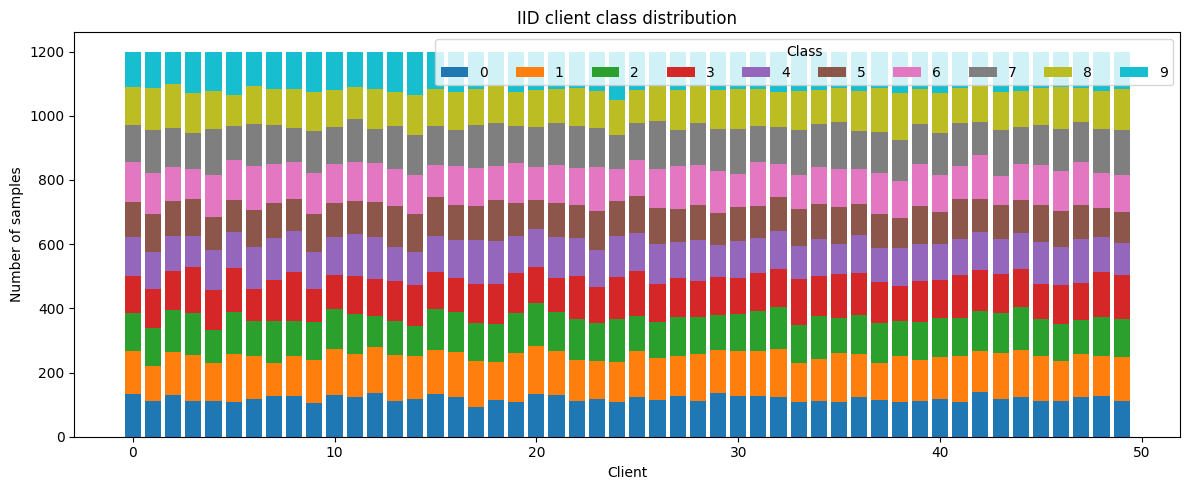

Client sizes: [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200]
Partition: /content/drive/MyDrive/FLasIRL(new)/data/mnist/partitions/IID/mnist_iid_50_seed42.pt


In [4]:
imbalance_mode = str(IMBALANCE_MODE).strip().lower()
if imbalance_mode not in {'none', 'global'}:
    raise ValueError("IMBALANCE_MODE phải là 'None' hoặc 'Global'.")

partition_stem = f'{DATASET_NAME}_iid_{NUM_CLIENTS}_seed{PARTITION_SEED}'
if imbalance_mode == 'global':
    partition_stem += '_global'
partition_path = PARTITION_DIR / f'{partition_stem}.pt'

if partition_path.exists():
    partition = torch.load(partition_path, map_location='cpu', weights_only=False)
    client_indices = partition['client_indices']
else:
    if imbalance_mode == 'global':
        labels_np = train_labels.cpu().numpy()
        rng = np.random.default_rng(PARTITION_SEED)
        selected = []
        for class_id, target_count in SAMPLES_PER_CLASS.items():
            class_indices = np.flatnonzero(labels_np == class_id)
            if target_count > len(class_indices):
                raise ValueError(
                    f'Class {class_id} chỉ có {len(class_indices):,} mẫu, '
                    f'không thể lấy {target_count:,} mẫu.'
                )
            rng.shuffle(class_indices)
            selected.extend(class_indices[:target_count].tolist())
        selected_indices = torch.tensor(selected, dtype=torch.long)
    else:
        selected_indices = torch.arange(len(train_labels), dtype=torch.long)

    generator = torch.Generator(device='cpu').manual_seed(PARTITION_SEED)
    shuffled = selected_indices[torch.randperm(len(selected_indices), generator=generator)]
    client_indices = list(torch.tensor_split(shuffled, NUM_CLIENTS))
    torch.save({
        'client_indices': client_indices,
        'seed': PARTITION_SEED,
        'num_clients': NUM_CLIENTS,
        'dataset_name': DATASET_NAME,
        'imbalance_mode': 'Global' if imbalance_mode == 'global' else 'None',
        'samples_per_class': SAMPLES_PER_CLASS if imbalance_mode == 'global' else None,
    }, partition_path)

partition_num_samples = sum(len(x) for x in client_indices)
assert len(torch.cat(client_indices).unique()) == partition_num_samples

client_class_counts = torch.zeros(NUM_CLIENTS, 10, dtype=torch.long)
for client_id, indices in enumerate(client_indices):
    client_class_counts[client_id] = torch.bincount(train_labels[indices], minlength=10)

plt.figure(figsize=(12, 5))
bottom = np.zeros(NUM_CLIENTS)
for cls in range(10):
    values = client_class_counts[:, cls].numpy()
    plt.bar(np.arange(NUM_CLIENTS), values, bottom=bottom, label=str(cls))
    bottom += values
plt.xlabel('Client')
plt.ylabel('Number of samples')
plt.title(f'{IMBALANCE_MODE} client class distribution')
plt.legend(ncol=10, title='Class')
plt.tight_layout()
partition_chart = PARTITION_DIR / f'partition_{NUM_CLIENTS}_clients_seed{PARTITION_SEED}.png'
plt.savefig(partition_chart, dpi=150)
plt.show()
print('Client sizes:', [len(x) for x in client_indices])
print('Partition:', partition_path)


In [5]:
class SmallCNN(nn.Module):
    def __init__(self, in_channels=1, input_size=28):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        feature_size = input_size
        feature_size = (feature_size - 5 + 1) // 2
        feature_size = (feature_size - 5 + 1) // 2
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * feature_size * feature_size, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class LinearProbe(nn.Module):
    def __init__(self, embedding_dim=512):
        super().__init__()
        self.linear = nn.Linear(embedding_dim, 10)

    def forward(self, x):
        return self.linear(x)


class RawLogisticRegression(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 10)

    def forward(self, x):
        return self.linear(x)


def embedding_cache_filename(split):
    key = f'{DATASET_NAME}_resnet18_imagenet1k_v1_resize{RESNET_SIZE}_imagenet_norm_{split}'
    h = hashlib.sha256(key.encode()).hexdigest()[:8]
    return f'resnet18_sz{RESNET_SIZE}_{split}_{h}.pt'


def preprocess_resnet(images):
    x = images.unsqueeze(1).repeat(1, 3, 1, 1) if DATASET_NAME == 'mnist' else images
    x = F.interpolate(x, size=(RESNET_SIZE, RESNET_SIZE), mode='bilinear', align_corners=False)
    return (x - IMAGENET_MEAN) / IMAGENET_STD


def make_embeddings(images, backbone):
    backbone.eval()
    output = []
    with torch.no_grad():
        for start in range(0, len(images), EMBED_BATCH_SIZE):
            batch = preprocess_resnet(images[start:start + EMBED_BATCH_SIZE].to(DEVICE))
            output.append(backbone(batch).float().cpu())
    return torch.cat(output)


if MODEL_NAME == 'resnet_linear':
    train_embed_path = DATA_DIR / embedding_cache_filename('train')
    test_embed_path = DATA_DIR / embedding_cache_filename('test')
    if train_embed_path.exists() and test_embed_path.exists():
        train_features = torch.load(train_embed_path, map_location='cpu')
        test_features = torch.load(test_embed_path, map_location='cpu')
    else:
        weights = models.ResNet18_Weights.IMAGENET1K_V1
        backbone = models.resnet18(weights=weights).to(DEVICE)
        backbone.fc = nn.Identity()
        for parameter in backbone.parameters():
            parameter.requires_grad_(False)
        train_features = make_embeddings(train_images, backbone)
        test_features = make_embeddings(test_images, backbone)
        torch.save(train_features, train_embed_path)
        torch.save(test_features, test_embed_path)
        del backbone
        torch.cuda.empty_cache()
    train_features = train_features.to(DEVICE)
    test_features = test_features.to(DEVICE)
    print('Cached embeddings:', train_features.shape, test_features.shape)


def build_model():
    if MODEL_NAME == 'cnn':
        model = SmallCNN(INPUT_CHANNELS, INPUT_SIZE)
    elif MODEL_NAME == 'logreg_raw':
        model = RawLogisticRegression(INPUT_CHANNELS * INPUT_SIZE * INPUT_SIZE)
    else:
        model = LinearProbe(512)
    return model.to(DEVICE)

seed_everything(MODEL_SEED)
global_model = build_model()
print(global_model)


SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [6]:
def batch_seed(round_id, client_id, local_epoch):
    return BATCH_SEED + round_id * 1_000_000 + client_id * 1_000 + local_epoch


def select_clients(round_id):
    if CLIENTS_PER_ROUND == NUM_CLIENTS:
        return list(range(NUM_CLIENTS))
    generator = torch.Generator(device='cpu').manual_seed(SELECTION_SEED + round_id)
    return torch.randperm(NUM_CLIENTS, generator=generator)[:CLIENTS_PER_ROUND].tolist()


def local_train(model, global_state, client_id, round_id):
    model.load_state_dict(global_state)
    model.train()
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
    indices = client_indices[client_id]
    for local_epoch in range(LOCAL_EPOCHS):
        generator = torch.Generator(device='cpu').manual_seed(batch_seed(round_id, client_id, local_epoch))
        permutation = indices[torch.randperm(len(indices), generator=generator)].to(DEVICE)
        for start in range(0, len(permutation), BATCH_SIZE):
            batch_indices = permutation[start:start + BATCH_SIZE]
            logits = model(train_features[batch_indices])
            loss = F.cross_entropy(logits, train_labels_gpu[batch_indices])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
    return {name: parameter.detach().clone() for name, parameter in model.named_parameters()}, len(indices)


@torch.no_grad()
def fedavg(client_states, client_sizes):
    total = float(sum(client_sizes))
    result = {}
    for name in client_states[0]:
        result[name] = sum(state[name] * (size / total) for state, size in zip(client_states, client_sizes))
    return result


@torch.no_grad()
def evaluate(model, features, labels):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    for start in range(0, len(labels), EVAL_BATCH_SIZE):
        x = features[start:start + EVAL_BATCH_SIZE]
        y = labels[start:start + EVAL_BATCH_SIZE]
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction='sum').item()
        total_correct += (logits.argmax(dim=1) == y).sum().item()
    return total_loss / len(labels), total_correct / len(labels)


METRIC_FIELDS = ['round', 'global_train_loss', 'global_train_accuracy', 'test_loss', 'test_accuracy', 'learning_rate', 'num_clients', 'num_selected_clients', 'selected_clients', 'num_samples']


def load_metrics():
    if not METRICS_PATH.exists():
        return []
    with METRICS_PATH.open(newline='') as handle:
        return list(csv.DictReader(handle))


def truncate_metrics(round_id):
    rows = [row for row in load_metrics() if int(row['round']) <= round_id]
    tmp_path = METRICS_PATH.with_suffix('.tmp')
    with tmp_path.open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=METRIC_FIELDS)
        writer.writeheader()
        writer.writerows(rows)
    os.replace(tmp_path, METRICS_PATH)


def append_metric(row):
    exists = METRICS_PATH.exists()
    with METRICS_PATH.open('a', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=METRIC_FIELDS)
        if not exists:
            writer.writeheader()
        writer.writerow(row)
        handle.flush()
        os.fsync(handle.fileno())


def save_checkpoint(round_id, model, selected_clients):
    checkpoint = {
        'round': round_id,
        'model_state': {name: value.detach().cpu() for name, value in model.named_parameters()},
        'partition_seed': PARTITION_SEED,
        'model_seed': MODEL_SEED,
        'batch_seed': BATCH_SEED,
        'selection_seed': SELECTION_SEED,
        'selected_clients': selected_clients,
        'config': {'model_name': MODEL_NAME, 'num_clients': NUM_CLIENTS, 'clients_per_round': CLIENTS_PER_ROUND, 'local_epochs': LOCAL_EPOCHS, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE},
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_state': torch.cuda.get_rng_state_all(),
    }
    tmp_path = CHECKPOINT_PATH.with_suffix('.pt.tmp')
    torch.save(checkpoint, tmp_path)
    os.replace(tmp_path, CHECKPOINT_PATH)


current_config = {
    'model_name': MODEL_NAME,
    'dataset_name': DATASET_NAME,
    'imbalance_mode': IMBALANCE_MODE,
    'num_clients': NUM_CLIENTS,
    'clients_per_round': CLIENTS_PER_ROUND,
    'local_epochs': LOCAL_EPOCHS,
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'resnet_size': RESNET_SIZE,
    'partition_seed': PARTITION_SEED,
    'model_seed': MODEL_SEED,
    'batch_seed': BATCH_SEED,
    'selection_seed': SELECTION_SEED,
}

start_round = 1
if CHECKPOINT_PATH.exists():
    if CONFIG_PATH.exists():
        with CONFIG_PATH.open('r') as handle:
            saved_config = json.load(handle)
        mismatches = []
        for key, current_val in current_config.items():
            if key in saved_config and saved_config[key] != current_val:
                mismatches.append(f"  - {key}: đã lưu = {saved_config[key]}, hiện tại = {current_val}")
        if mismatches:
            next_id = RUN_ID + 1 if isinstance(RUN_ID, int) else f"{RUN_ID}_new"
            raise ValueError(
                f"Lỗi: Cấu hình của Run {RUN_ID} đã bị thay đổi so với lần chạy trước!\n"
                f"Các thông số không khớp:\n" + "\n".join(mismatches) + "\n"
                f"-> Nếu muốn thử nghiệm cấu hình mới, hãy đổi sang RUN_ID mới (ví dụ: RUN_ID={next_id})."
            )
        saved_config['rounds'] = ROUNDS
        with CONFIG_PATH.open('w') as handle:
            json.dump(saved_config, handle, indent=2)

    checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
    global_model.load_state_dict(checkpoint['model_state'], strict=True)
    torch.set_rng_state(checkpoint['torch_rng_state'])
    torch.cuda.set_rng_state_all(checkpoint['cuda_rng_state'])
    completed_round = checkpoint['round']
    truncate_metrics(completed_round)
    start_round = completed_round + 1
    if start_round > ROUNDS:
        print(f"Run {RUN_ID} đã hoàn thành toàn bộ {completed_round} rounds (ROUNDS hiện tại = {ROUNDS}). Hãy tăng ROUNDS nếu muốn train tiếp.")
    else:
        print(f"Phát hiện checkpoint của Run {RUN_ID} (round {completed_round}). Đang tiếp tục huấn luyện đến round {ROUNDS}...")
else:
    full_config = {
        'run_id': RUN_ID,
        'run_dir': str(RUN_DIR),
        'rounds': ROUNDS,
        **current_config,
        'partition_path': str(partition_path),
        'device': str(DEVICE),
    }
    with CONFIG_PATH.open('w') as handle:
        json.dump(full_config, handle, indent=2)
    print(f"Bắt đầu Run {RUN_ID} mới từ round 1 đến {ROUNDS}...")

# Single local model reused across clients to reduce allocation churn
worker_model = build_model()

for round_id in range(start_round, ROUNDS + 1):
    round_start = time.time()
    selected_clients = select_clients(round_id)
    global_state = {name: parameter.detach().clone() for name, parameter in global_model.named_parameters()}
    client_states, client_sizes = [], []
    for client_id in selected_clients:
        state, size = local_train(worker_model, global_state, client_id, round_id)
        client_states.append(state)
        client_sizes.append(size)
    global_model.load_state_dict(fedavg(client_states, client_sizes), strict=True)
    global_train_loss, global_train_accuracy = evaluate(global_model, train_features, train_labels_gpu)
    test_loss, test_accuracy = evaluate(global_model, test_features, test_labels_gpu)
    row = {
        'round': round_id,
        'global_train_loss': global_train_loss,
        'global_train_accuracy': global_train_accuracy,
        'test_loss': test_loss,
        'test_accuracy': test_accuracy,
        'learning_rate': LEARNING_RATE,
        'num_clients': NUM_CLIENTS,
        'num_selected_clients': len(selected_clients),
        'selected_clients': json.dumps(selected_clients),
        'num_samples': sum(client_sizes)
    }
    append_metric(row)
    save_checkpoint(round_id, global_model, selected_clients)
    print(f'Round {round_id:02d}/{ROUNDS} | clients {selected_clients} | train loss {global_train_loss:.4f} (acc {global_train_accuracy:.2%}) | test loss {test_loss:.4f} (acc {test_accuracy:.2%}) | {time.time() - round_start:.1f}s')

del worker_model
torch.save({name: value.detach().cpu() for name, value in global_model.named_parameters()}, RUN_DIR / 'final_model_parameters.pt')
print('Finished. Results:', RUN_DIR)


Bắt đầu Run 12 mới từ round 1 đến 50...
Round 01/50 | clients [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49] | train loss 2.1658 (acc 50.92%) | test loss 2.1631 (acc 50.81%) | 9.3s
Round 02/50 | clients [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49] | train loss 1.6483 (acc 70.70%) | test loss 1.6381 (acc 71.34%) | 5.3s
Round 03/50 | clients [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49] | train loss 0.7229 (acc 83.30%) | test loss 0.7002 (acc 84.35%) | 5.4s
Round 04/50 | clients [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 

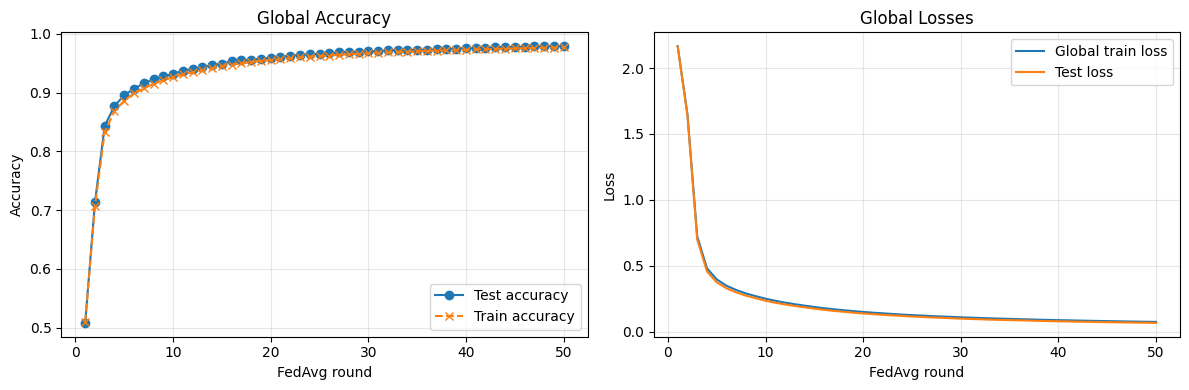

Final test accuracy (primary): 0.979
Best test accuracy (secondary diagnostic): 0.979
Summary saved to: /content/drive/MyDrive/FLasIRL(new)/baseline/run12/summary.json


In [7]:
# Load and plot a completed or partially completed run
plot_run_id = RUN_ID  # e.g. 1, 'run1', or set to an existing run ID
plot_run_dir = RUN_DIR if plot_run_id == RUN_ID else BASELINE_DIR / (str(plot_run_id) if str(plot_run_id).startswith('run') else f'run{plot_run_id}')
plot_metrics_path = plot_run_dir / 'metrics.csv'

if not plot_metrics_path.exists():
    print(f'No metrics found at {plot_metrics_path}')
else:
    with plot_metrics_path.open(newline='') as handle:
        rows = list(csv.DictReader(handle))
    if not rows:
        print('Metrics file is empty.')
    else:
        rounds = [int(row['round']) for row in rows]
        accuracy = [float(row['test_accuracy']) for row in rows]
        train_accuracy = [float(row['global_train_accuracy']) for row in rows] if 'global_train_accuracy' in rows[0] else None
        train_loss = [float(row['global_train_loss']) for row in rows]
        test_loss = [float(row['test_loss']) for row in rows]

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(rounds, accuracy, marker='o', label='Test accuracy')
        if train_accuracy:
            axes[0].plot(rounds, train_accuracy, marker='x', linestyle='--', label='Train accuracy')
            axes[0].legend()
        axes[0].set(xlabel='FedAvg round', ylabel='Accuracy', title='Global Accuracy')
        axes[0].grid(True, alpha=0.3)

        axes[1].plot(rounds, train_loss, label='Global train loss')
        axes[1].plot(rounds, test_loss, label='Test loss')
        axes[1].set(xlabel='FedAvg round', ylabel='Loss', title='Global Losses')
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        plt.tight_layout()

        result_chart = plot_run_dir / 'metrics.png'
        plt.savefig(result_chart, dpi=150)
        plt.show()

        summary = {
            'run_id': plot_run_id,
            'run_dir': str(plot_run_dir),
            'model_name': MODEL_NAME,
            'completed_rounds': len(rounds),
            'final_test_accuracy': accuracy[-1],
            'best_test_accuracy': max(accuracy),
            'final_train_loss': train_loss[-1],
            'final_test_loss': test_loss[-1],
        }
        if train_accuracy:
            summary['final_train_accuracy'] = train_accuracy[-1]

        summary_path = plot_run_dir / 'summary.json'
        with summary_path.open('w') as handle:
            json.dump(summary, handle, indent=2)

        print('Final test accuracy (primary):', accuracy[-1])
        print('Best test accuracy (secondary diagnostic):', max(accuracy))
        print('Summary saved to:', summary_path)
